# Dummy S1 optical propagation timing map (optical toy Monte Carlo)

After an S1 photon is emitted, it needs some time to reach a PMT. Light travels about 18 cm per ns in liquid xenon. Photons that hit a PMT directly arrive after a few ns. Photons that are scattered in the xenon, reflected on the PTFE walls or reflected at the liquid surface (total internal reflection) arrive after tens of ns. This **optical propagation delay** broadens the S1 pulse and differs between the top and the bottom PMT array.

The ember plugin `S1PhotonPropagation` (like fuse) draws this delay from a **timing map**. In a real experiment the map comes from an optical photon simulation (e.g. Geant4). This notebook builds the map with a small **optical toy Monte Carlo** (`ember.optical_toy_mc`) that tracks single photons through a cylindrical TPC. The optical parameters are taken from

> K. Böse, *From Electronic Recoil Background and Optical Modeling in XENONnT to Infrared Emission in Xenon Detectors*, PhD thesis, Heidelberg University (2026), Chapter 4.

> **Replace this map** with the result of a full optical simulation of your detector if you have one. The toy Monte Carlo is a strong simplification (see the limitations below).

### The optical toy Monte Carlo

Each photon starts at a position in the TPC with a random (isotropic) direction and is tracked until it is absorbed or reaches a photocathode:

| Process | Model | Parameter in `detector.yaml` |
|---|---|---|
| Speed of light in the liquid | $c/n$ | `lxe_refractive_index` |
| Rayleigh scattering in the liquid | exponential free path, angle $\propto 1 + \cos^2\theta$ | `lxe_rayleigh_scattering_length` |
| Absorption (impurities) | exponential free path in liquid and gas | `lxe_absorption_length`, `gxe_absorption_length` |
| PTFE walls | diffuse (Lambertian) reflection, otherwise absorbed | `ptfe_reflectivity_liquid`, `ptfe_reflectivity_gas` |
| Liquid surface | Fresnel reflection and refraction, total internal reflection above $\arcsin(1/n) \approx 38°$ | `lxe_refractive_index` |
| PMT arrays | flat planes; a photon hits a photocathode with the probability $n_\mathrm{PMT} (d/2)^2 / R^2$, otherwise PTFE | `pmt_photocathode_diameter`, `n_top_pmts`, `n_bottom_pmts` |

The delay of a detected photon is its path length in the liquid times $n/c$ plus its path length in the gas divided by $c$. The quantum efficiency of the PMTs does not change the delay distribution, so it is not needed here.

The default parameters are Böse's best fit "SR1 normalized $g_1$, timing included" (Table 4.9): $n = 1.63$, $\lambda_\mathrm{scat} = 32$ cm, $\lambda_\mathrm{abs} = 12.45$ m, $R_\mathrm{PTFE} = 100\,\%$ in the liquid and $80\,\%$ in the gas. Of the parameter sets in the thesis, this is the one that reproduces the measured difference of the S1 arrival times in the top and bottom array of XENONnT ($^{83m}$Kr data, Figs. 4.17 and 4.36). The scattering length of about 30 cm also agrees with the literature (Table 4.1).

**Limitations.** Electrodes, the optics of the PMT windows, the specular part of the PTFE reflection and the exact PMT positions are not modelled. Compared with Böse's Geant4 simulation, the mean delays agree within a few ns. For interactions close to one array, the delay tail of the other array is somewhat too long: the top-bottom difference of the 10-90 % rise time near the bottom is about 26 ns instead of 16 ns.

### Format of the timing map

The map stores, for each depth $z$ and each PMT array, the delay distribution as an **inverse cumulative distribution function** (inverse CDF):

$$t_\mathrm{delay} = F_z^{-1}(u), \qquad u \in [0, 1].$$

For a uniform random number $u$, the map returns the delay below which a fraction $u$ of the photons arrive. Drawing $u$ uniformly therefore produces delays with the right distribution (inverse transform sampling). The map has

| Key | Content |
|---|---|
| `coordinate_system` | Two axes: `[['z', (z_min, z_max, n_z)], ['u', (0, 1, n_u)]]`, evenly spaced. |
| `top` | Delays in ns for photons detected by the top array, shape `(n_z, n_u)`. |
| `bottom` | Delays in ns for photons detected by the bottom array, shape `(n_z, n_u)`. |
| `name`, `description`, `timestamp` | Metadata. |

For every $z$, the delays must not decrease with $u$. The plugin calls the map with positions `(z, u)` and `map_name="top"` or `"bottom"`, depending on the channel of the photon.

The map is built exactly like it would be from a Geant4 simulation: for every $z$ slice, photons are emitted uniformly over the cross section of the TPC. For each array, the quantiles of the arrival times of the detected photons at the grid values of $u$ are stored (`np.quantile(times, u_grid)`).

In [1]:
import dataclasses
import time

import matplotlib.pyplot as plt
import numpy as np

from ember.maps import load_map, save_map_data
from ember.optical_toy_mc import (
    OUTCOME_BOTTOM,
    OUTCOME_TOP,
    TpcOptics,
    build_s1_timing_map,
    draw_positions_in_disk,
    simulate_photons,
)
from ember.url_protocols import DUMMY_MAP_DIRECTORY

The geometry and the optical parameters are read from ember's `detector.yaml`. The map covers the full liquid xenon, from the bottom PMTs to the liquid surface.

In [2]:
optics = TpcOptics.from_detector_config()
for name, value in dataclasses.asdict(optics).items():
    print(f"{name:32s} {value:.4g}")

tpc_radius                       66.4
z_bottom_pmts                    -154.7
z_liquid_level                   0.5116
z_top_pmts                       7.394
lxe_refractive_index             1.63
lxe_rayleigh_scattering_length   32
lxe_absorption_length            1245
gxe_absorption_length            1245
ptfe_reflectivity_liquid         1
ptfe_reflectivity_gas            0.8013
photocathode_coverage_top        0.5876
photocathode_coverage_bottom     0.5597


Build the map on a grid of 32 depths and 501 values of $u$, with $2 \cdot 10^5$ photons per depth, and save it. This takes about a minute.

In [3]:
timing_map = build_s1_timing_map(
    optics,
    number_of_z_points=32,
    number_of_u_points=501,
    photons_per_slice=200_000,
    seed=0,
)
timing_map["name"] = "Dummy S1 optical propagation timing map"
timing_map["timestamp"] = time.time()

output_file = DUMMY_MAP_DIRECTORY / "s1_optical_propagation_dummy.json"
save_map_data(timing_map, output_file)
print("Saved", output_file)

Saved /mnt/d/XLZD/mymodules/ember/ember/dummy_maps/s1_optical_propagation_dummy.json


### Check the map

Load the map the same way the plugin does and plot the cumulative distribution of the delay for a few depths. Close to an array, many photons arrive directly within a few ns. Far away from it, the earliest photons arrive after the direct flight time and most photons after several scatters and reflections.

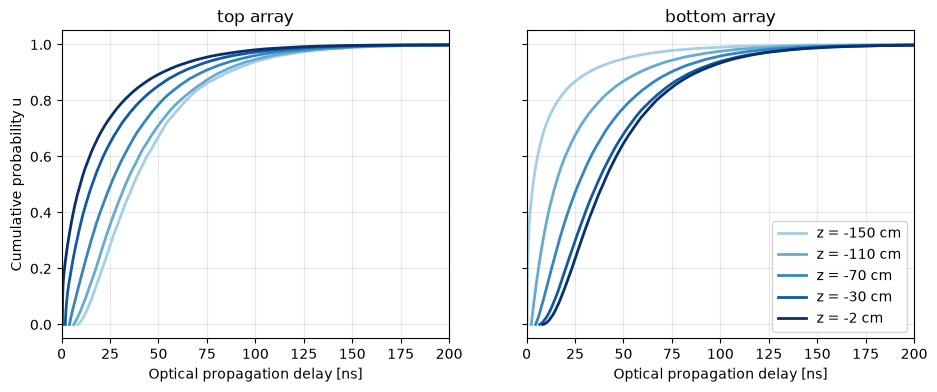

In [4]:
itp_map = load_map(output_file)

u_values = np.linspace(0, 1, 501)
depths = [-150.0, -110.0, -70.0, -30.0, -2.0]
colors = plt.cm.Blues(np.linspace(0.35, 1.0, len(depths)))

figure, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for axis, array_name in zip(axes, ["top", "bottom"]):
    for depth, color in zip(depths, colors):
        z_and_u = np.column_stack([np.full(len(u_values), depth), u_values])
        delays = itp_map(z_and_u, map_name=array_name)
        axis.plot(delays, u_values, color=color, linewidth=2, label=f"z = {depth:.0f} cm")
    axis.set_xlim(0, 200)
    axis.set_xlabel("Optical propagation delay [ns]")
    axis.set_title(f"{array_name} array")
    axis.grid(alpha=0.3)
axes[0].set_ylabel("Cumulative probability u")
axes[1].legend()
plt.show()

The median delay and the delay below which 90 % of the photons arrive, as a function of depth. The top array sees later light from deep interactions, the bottom array from shallow ones:

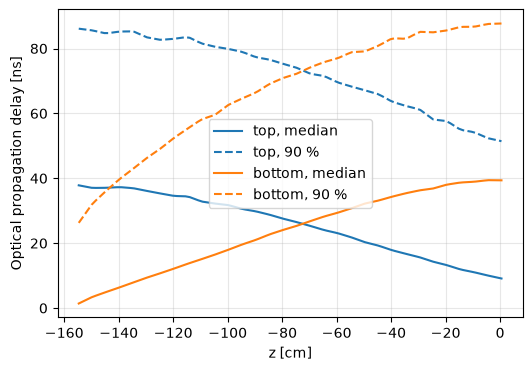

In [5]:
z_values = np.linspace(optics.z_bottom_pmts, optics.z_liquid_level, 100)
median_positions = np.column_stack([z_values, np.full(100, 0.5)])
q90_positions = np.column_stack([z_values, np.full(100, 0.9)])

plt.figure(figsize=(6, 4))
plt.plot(z_values, itp_map(median_positions, map_name="top"), color="C0", label="top, median")
plt.plot(z_values, itp_map(q90_positions, map_name="top"), color="C0", linestyle="--", label="top, 90 %")
plt.plot(z_values, itp_map(median_positions, map_name="bottom"), color="C1", label="bottom, median")
plt.plot(z_values, itp_map(q90_positions, map_name="bottom"), color="C1", linestyle="--", label="bottom, 90 %")
plt.xlabel("z [cm]")
plt.ylabel("Optical propagation delay [ns]")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

Check that the delays never decrease with $u$:

In [6]:
for array_name in ["top", "bottom"]:
    delays_are_sorted = np.all(np.diff(timing_map[array_name], axis=1) >= 0)
    print(array_name, "non-decreasing in u:", delays_are_sorted)

top non-decreasing in u: True
bottom non-decreasing in u: True


### Comparison with the Geant4 simulation of XENONnT

Böse's thesis shows results of the XENONnT Geant4 optical simulation that we can compare with. Like in the thesis, photons are emitted at $r < 63$ cm and $z$ between $-140$ and $-20$ cm:

* **Centre-time difference** (Fig. 4.36): mean arrival time of the photons in the top array minus the one in the bottom array. Geant4 with the parameters used here: about $+30$ ns at $z = -140$ cm and $-26$ ns at $z = -20$ cm, in agreement with $^{83m}$Kr data. Geant4 with $\lambda_\mathrm{scat} = 50$ cm: about $+17$ ns and $-18$ ns.
* **AFT** (Fig. 4.3, SR1 parameter set of Table 4.4: $n = 1.69$, $\lambda_\mathrm{scat} = 50$ cm, $\lambda_\mathrm{abs} = 18.77$ m, $R_\mathrm{PTFE} = 90\,\%$ / $100\,\%$): about 0.09 at $z = -140$ cm and 0.54 at $z = -15$ cm.
* **Photon paths** (Fig. 4.6, same SR1 set): detected photons travel on average 373 cm in the liquid and are reflected 2.8 times on PTFE in the liquid.

We run the toy Monte Carlo with both parameter sets. This takes a few seconds.

In [7]:
sr1_optics = dataclasses.replace(
    optics,
    lxe_refractive_index=1.69,
    lxe_rayleigh_scattering_length=50.0,
    lxe_absorption_length=1877.0,
    gxe_absorption_length=1877.0,
    ptfe_reflectivity_liquid=0.90,
    ptfe_reflectivity_gas=1.0,
)
comparison_depths = np.linspace(-140, -20, 13)
rng = np.random.default_rng(1)

results = {}
for label, parameter_set in [("timing set (default)", optics), ("SR1 set", sr1_optics)]:
    area_fraction_top, centre_time_difference, paths, reflections = [], [], [], []
    for depth in comparison_depths:
        positions = draw_positions_in_disk(depth, 100_000, 63.0, rng)
        photons = simulate_photons(positions, parameter_set, seed=int(rng.integers(2**31)))
        is_top = photons["outcome"] == OUTCOME_TOP
        is_bottom = photons["outcome"] == OUTCOME_BOTTOM
        is_detected = is_top | is_bottom
        area_fraction_top.append(is_top.sum() / is_detected.sum())
        centre_time_difference.append(
            photons["arrival_time"][is_top].mean() - photons["arrival_time"][is_bottom].mean()
        )
        paths.append(photons["path_liquid"][is_detected])
        reflections.append(photons["ptfe_reflections_liquid"][is_detected])
    results[label] = (area_fraction_top, centre_time_difference)
    print(
        f"{label:22s} mean path in the liquid {np.concatenate(paths).mean():5.0f} cm, "
        f"mean PTFE reflections in the liquid {np.concatenate(reflections).mean():.2f}"
    )

timing set (default)   mean path in the liquid   545 cm, mean PTFE reflections in the liquid 4.39
SR1 set                mean path in the liquid   417 cm, mean PTFE reflections in the liquid 3.10


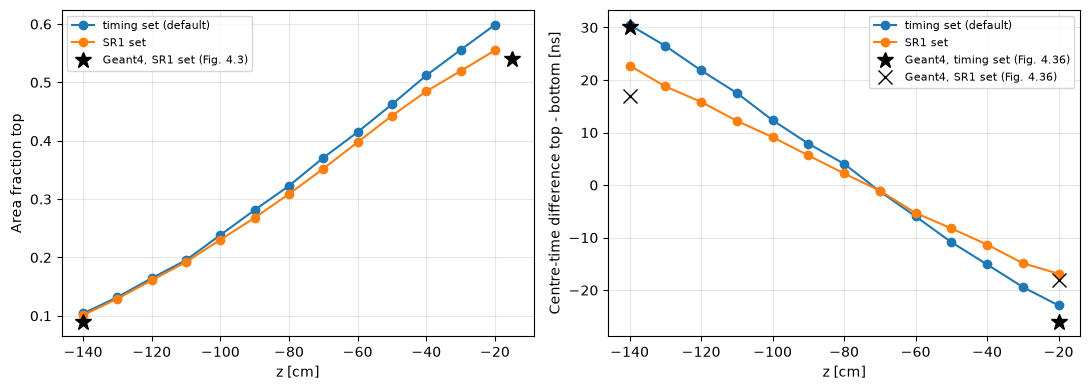

In [8]:
figure, axes = plt.subplots(1, 2, figsize=(11, 4))
for label, (area_fraction_top, centre_time_difference) in results.items():
    axes[0].plot(comparison_depths, area_fraction_top, marker="o", label=label)
    axes[1].plot(comparison_depths, centre_time_difference, marker="o", label=label)

axes[0].plot([-140, -15], [0.09, 0.54], "k*", markersize=12, label="Geant4, SR1 set (Fig. 4.3)")
axes[1].plot([-140, -20], [30, -26], "k*", markersize=12, label="Geant4, timing set (Fig. 4.36)")
axes[1].plot([-140, -20], [17, -18], "kx", markersize=10, label="Geant4, SR1 set (Fig. 4.36)")

axes[0].set_ylabel("Area fraction top")
axes[1].set_ylabel("Centre-time difference top - bottom [ns]")
for axis in axes:
    axis.set_xlabel("z [cm]")
    axis.grid(alpha=0.3)
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

The toy Monte Carlo reproduces the Geant4 results within about 10-20 %: the AFT, the photon path lengths and the centre-time difference, including its dependence on the scattering length. The map built above therefore describes the mean delays well. Its tails are somewhat too long, see the limitations above.

To build a map for another detector (e.g. XLZD-sized), change the geometry in `detector.yaml` and rerun this notebook. The optical parameters describe the materials and can stay the same, if the xenon purity and the PTFE are similar.